## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('../data/ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

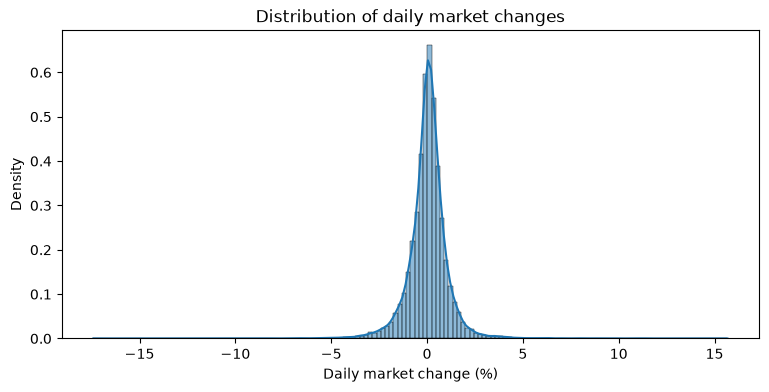

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

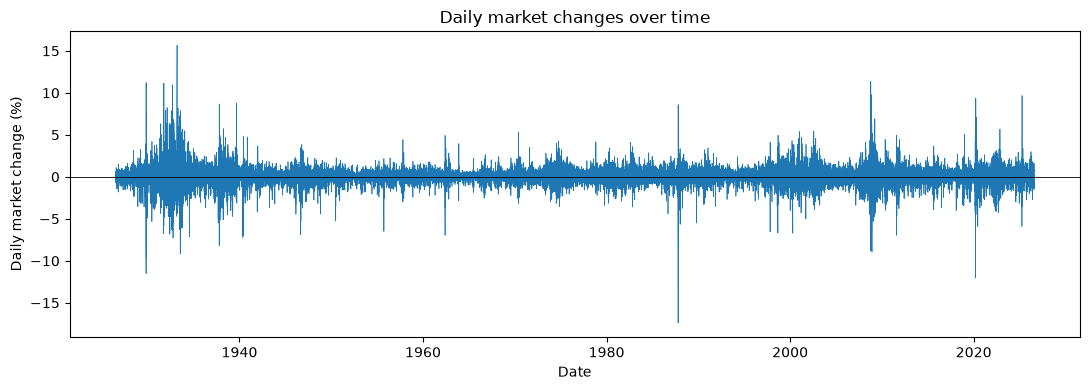

In [5]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [6]:
df['market_return_pct_i'] = (
    df['market_return_pct'] > 0
).where(df['market_return_pct'].notna())

df['y_t'] = df['market_return_pct_i'].map({
    True: 'Up',
    False: 'Down (and flat)'
})

df['y_tp1'] = df['market_return_pct_i'].shift(-1).map({
    True: 'Up',
    False: 'Down (and flat)'
})

In [7]:
# Joint PMF
tab_joint = pd.crosstab(
    df['y_t'],
    df['y_tp1'],
    normalize=True
)

display(tab_joint)

# Marginal PMF
tab_marginal = pd.crosstab(
    df['y_t'],
    df['y_tp1'],
    normalize=True,
    margins=True
)

display(tab_marginal)

# Conditional PMF
tab_conditional = pd.crosstab(
    df['y_t'],
    df['y_tp1'],
    normalize='index'
)

display(tab_conditional)

y_tp1,Down (and flat),Up
y_t,,
Down (and flat),0.224720,0.228142
Up,0.228142,0.318996


y_tp1,Down (and flat),Up,All
y_t,,,
Down (and flat),0.224720,0.228142,0.452862
Up,0.228142,0.318996,0.547138
All,0.452862,0.547138,1.000000


y_tp1,Down (and flat),Up
y_t,,
Down (and flat),0.496221,0.503779
Up,0.416974,0.583026


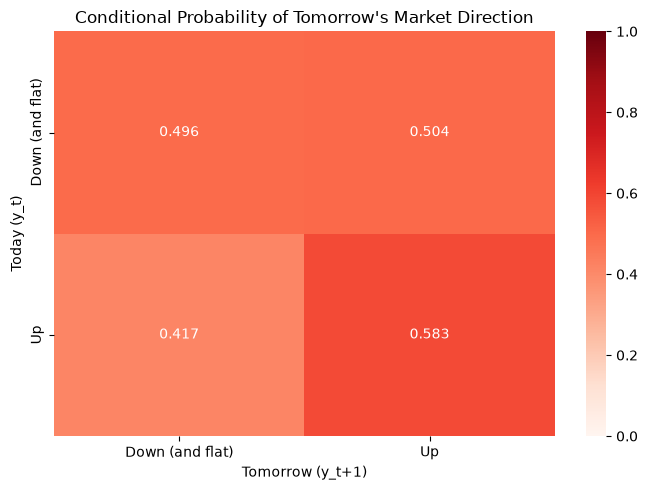

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))

sns.heatmap(
    tab_conditional,
    annot=True,
    fmt='.3f',
    cmap='Reds',
    vmin=0,
    vmax=1,
    ax=ax
)

ax.set(
    title='Conditional Probability of Tomorrow\'s Market Direction',
    xlabel='Tomorrow (y_t+1)',
    ylabel='Today (y_t)'
)

plt.tight_layout()
plt.show()

**Part 1: Two States — Interpretation**

Looking at the marginal PMF, an Up day is more common than a Down (and flat) day. Approximately 54.7% of the next trading days are Up, while 45.3% are Down or flat. This tells us that the market increased more often than it decreased or remained unchanged over the period studied.

However, the marginal probabilities alone do not tell us whether today's market direction helps predict tomorrow's direction. To investigate this, we look at the conditional PMF.

The conditional probabilities show that an Up day has approximately a 58.3% probability of being followed by another Up day and a 41.7% probability of being followed by a Down or flat day. When today's market is Down or flat, the probability of an Up day tomorrow is approximately 50.4%, compared with 49.6% for another Down or flat day.

This suggests that an Up day is somewhat more likely to be followed by another Up day than a Down or flat day is. The difference between the two probabilities of an Up day tomorrow is approximately 7.9 percentage points.

Overall, today's market direction provides some information about tomorrow's direction, particularly when today's market is Up. However, the relationship is not strong enough to make reliable predictions. Even after an Up day, there is still a substantial probability that the next trading day will be Down or flat. Therefore, today's category provides a modest indication of tomorrow's direction, but it does not make the market easy to predict.

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [9]:
df['pct_bin'] = pd.cut(
    df['market_return_pct'],
    bins=[-np.inf, -1, -0.1, 0.1, 1, np.inf],
    labels=['Large loss', 'Small loss', 'Near zero',
            'Small gain', 'Large gain']
)

df['y_t'] = df['pct_bin']
df['y_tp1'] = df['pct_bin'].shift(-1)

df['y_t'].value_counts().reindex([
    'Large loss', 'Small loss', 'Near zero',
    'Small gain', 'Large gain'
])

y_t
Large loss    2759
Small loss    7452
Near zero     3441
Small gain    9785
Large gain    2859
Name: count, dtype: int64

**Interpretation: Distribution of the Five Categories**

The five categories show that small market movements are more common than extreme gains or losses. Small gain is the most frequent category, with 9,785 observations, followed by small loss, with 7,452 observations. Near-zero returns occur 3,441 times, while large gains and large losses occur 2,859 and 2,759 times, respectively.

Overall, the distribution suggests that the market more frequently experiences relatively small daily gains or losses rather than extreme movements. Small gains are the most common category, while large losses are the least common.

In [10]:
# Joint PMF
tab_joint = pd.crosstab(
    df['y_t'],
    df['y_tp1'],
    normalize=True
)

display(tab_joint)

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
y_t,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928


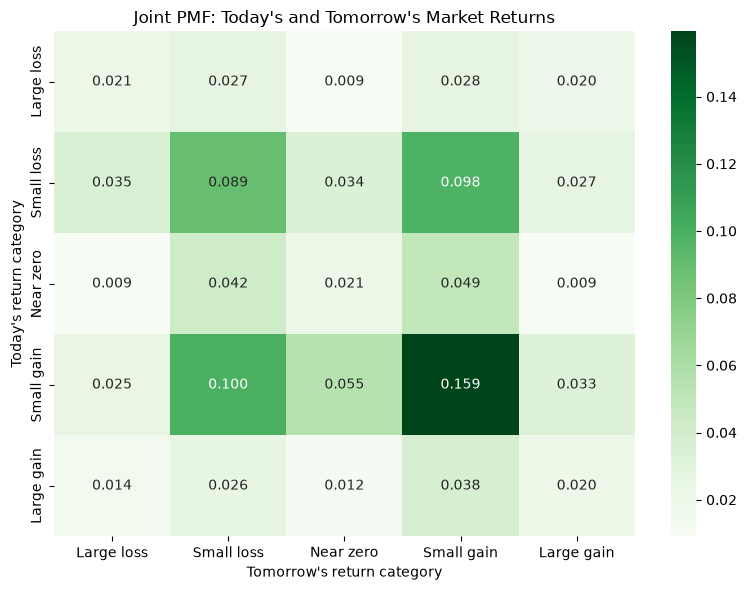

In [11]:
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    tab_joint,
    annot=True,
    fmt='.3f',
    cmap='Greens',
    ax=ax
)

ax.set(
    title="Joint PMF: Today's and Tomorrow's Market Returns",
    xlabel="Tomorrow's return category",
    ylabel="Today's return category"
)

plt.tight_layout()
plt.show()

In [12]:
# Marginal PMF
tab_marginal = pd.crosstab(
    df['y_t'],
    df['y_tp1'],
    normalize=True,
    margins=True
)

display(tab_marginal)

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
y_t,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


**Interpretation: Joint and Marginal PMFs**

The joint and marginal PMFs show that small gains are the most common next-day outcome. The largest individual joint probability is the combination of a small gain today followed by another small gain tomorrow, with a probability of approximately 15.94%. This indicates that consecutive small-gain days are the most frequently observed combination among the five categories.

Looking at the marginal PMF, a small gain is the most likely next-day category, with a probability of approximately 37.21%, followed by a small loss at approximately 28.34%. Together, small gains and small losses account for approximately 65.55% of next-day outcomes.

Although these results show that small gains are relatively common, the joint and marginal probabilities alone do not establish how strongly today's category influences tomorrow's category. To investigate that relationship, we next examine the conditional PMF.

In [13]:
# Get the actual market return for the next trading day
df['market_return_pct_tp1'] = df['market_return_pct'].shift(-1)

# Calculate descriptive statistics for tomorrow's returns,
# grouped by today's return category
tomorrow_stats = (
    df.groupby('y_t', observed=False)['market_return_pct_tp1']
      .describe()
)

display(tomorrow_stats)

,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


**Conditional Expected Returns and Volatility**

Using `.groupby()` and `.describe()`, I calculated tomorrow's returns based on today's market category. The expected returns range from -0.0438% following a Small loss to +0.1631% following a Large gain. Overall, the expected returns are relatively close to zero.

The most extreme negative next-day return is -17.41% following a Large loss, while the most extreme positive return is +15.67% following a Large gain. In terms of volatility, Large loss has the highest standard deviation (1.7206), followed by Large gain (1.3841). Near zero and Small gain have the lowest standard deviations (0.8261 and 0.8322).

These results suggest that large market movements, particularly losses, tend to be followed by greater volatility, while smaller movements are associated with more stable next-day returns. However, the relatively small expected returns compared with the variability suggest that today's category alone is not enough to reliably predict tomorrow's return.

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [14]:
# Divide daily market returns into 21 quantile-based bins
df['pct_bin_21'] = pd.qcut(
    df['market_return_pct'],
    q=21
)

# Identify today's and tomorrow's return categories
df['y_t'] = df['pct_bin_21']
df['y_tp1'] = df['pct_bin_21'].shift(-1)

# Display the number of observations in each bin
df['y_t'].value_counts().sort_index()

y_t
(-17.411, -1.61]    1255
(-1.61, -1.07]      1253
(-1.07, -0.78]      1286
(-0.78, -0.57]      1280
(-0.57, -0.42]      1230
(-0.42, -0.3]       1226
(-0.3, -0.19]       1371
(-0.19, -0.11]      1206
(-0.11, -0.03]      1198
(-0.03, 0.04]       1331
(0.04, 0.11]        1210
(0.11, 0.18]        1223
(0.18, 0.26]        1294
(0.26, 0.34]        1223
(0.34, 0.44]        1310
(0.44, 0.54]        1193
(0.54, 0.67]        1211
(0.67, 0.84]        1283
(0.84, 1.09]        1225
(1.09, 1.55]        1250
(1.55, 15.67]       1238
Name: count, dtype: int64

In [15]:
# Calculate the joint PMF
joint_21 = pd.crosstab(
    df['y_t'],
    df['y_tp1'],
    normalize=True
)

display(joint_21)

y_tp1,"(-17.411, -1.61]","(-1.61, -1.07]","(-1.07, -0.78]","(-0.78, -0.57]","(-0.57, -0.42]","(-0.42, -0.3]","(-0.3, -0.19]","(-0.19, -0.11]","(-0.11, -0.03]","(-0.03, 0.04]",...,"(0.11, 0.18]","(0.18, 0.26]","(0.26, 0.34]","(0.34, 0.44]","(0.44, 0.54]","(0.54, 0.67]","(0.67, 0.84]","(0.84, 1.09]","(1.09, 1.55]","(1.55, 15.67]"
y_t,,,,,,,,,,,,,,,,,,,,,
"(-17.411, -1.61]",0.006959,0.003651,0.002928,0.001787,0.002206,0.001749,0.001825,0.001141,0.001369,0.001331,...,0.001027,0.001331,0.001331,0.001103,0.001597,0.001141,0.001940,0.002016,0.003613,0.006883
"(-1.61, -1.07]",0.004868,0.003385,0.003195,0.002206,0.002320,0.001978,0.002206,0.001673,0.001445,0.002320,...,0.001559,0.001331,0.001521,0.001711,0.001597,0.001825,0.001825,0.002890,0.002510,0.003651
"(-1.07, -0.78]",0.003651,0.003765,0.003727,0.003803,0.002244,0.001863,0.002130,0.001825,0.001483,0.002054,...,0.001978,0.002358,0.002244,0.001635,0.001369,0.002054,0.001825,0.002320,0.002510,0.002662
"(-0.78, -0.57]",0.002814,0.003689,0.003080,0.002776,0.002700,0.002472,0.002358,0.001559,0.002130,0.002396,...,0.001787,0.001940,0.001521,0.002282,0.002130,0.002282,0.001787,0.002434,0.002548,0.002092
"(-0.57, -0.42]",0.002320,0.002700,0.002890,0.002586,0.002130,0.002548,0.002624,0.002168,0.002320,0.001825,...,0.002054,0.001863,0.001749,0.002738,0.002168,0.001940,0.002662,0.001635,0.002282,0.001863
"(-0.42, -0.3]",0.002054,0.002852,0.002510,0.002890,0.002738,0.002206,0.002282,0.002434,0.001940,0.002130,...,0.001863,0.002206,0.002092,0.001940,0.002054,0.002586,0.002624,0.001559,0.001940,0.001940
"(-0.3, -0.19]",0.002396,0.002814,0.003347,0.003195,0.002814,0.002814,0.002206,0.002244,0.002434,0.002472,...,0.001940,0.002586,0.003195,0.002510,0.002130,0.002510,0.001940,0.001749,0.002396,0.001673
"(-0.19, -0.11]",0.001521,0.002358,0.002434,0.003156,0.002168,0.002358,0.002776,0.002434,0.001902,0.002282,...,0.002358,0.002472,0.001863,0.002206,0.002206,0.001521,0.001940,0.001863,0.001978,0.001179
"(-0.11, -0.03]",0.001331,0.002016,0.002434,0.002434,0.002510,0.002472,0.002320,0.002472,0.002358,0.002738,...,0.002472,0.002434,0.002206,0.002510,0.002358,0.001902,0.002130,0.001787,0.001445,0.001521


In [16]:
# Subtract the uniform joint probability baseline
joint_21_subtract = joint_21 - (1 / 21**2)

display(joint_21_subtract)

y_tp1,"(-17.411, -1.61]","(-1.61, -1.07]","(-1.07, -0.78]","(-0.78, -0.57]","(-0.57, -0.42]","(-0.42, -0.3]","(-0.3, -0.19]","(-0.19, -0.11]","(-0.11, -0.03]","(-0.03, 0.04]",...,"(0.11, 0.18]","(0.18, 0.26]","(0.26, 0.34]","(0.34, 0.44]","(0.44, 0.54]","(0.54, 0.67]","(0.67, 0.84]","(0.84, 1.09]","(1.09, 1.55]","(1.55, 15.67]"
y_t,,,,,,,,,,,,,,,,,,,,,
"(-17.411, -1.61]",0.004692,0.001383,0.000661,-0.000480,-0.000062,-0.000518,-0.000442,-0.001127,-0.000898,-0.000937,...,-0.001241,-0.000937,-0.000937,-0.001165,-0.000670,-0.001127,-0.000328,-0.000252,0.001345,0.004616
"(-1.61, -1.07]",0.002600,0.001117,0.000927,-0.000062,0.000052,-0.000290,-0.000062,-0.000594,-0.000822,0.000052,...,-0.000708,-0.000937,-0.000746,-0.000556,-0.000670,-0.000442,-0.000442,0.000623,0.000242,0.001383
"(-1.07, -0.78]",0.001383,0.001497,0.001459,0.001535,-0.000024,-0.000404,-0.000138,-0.000442,-0.000784,-0.000214,...,-0.000290,0.000090,-0.000024,-0.000632,-0.000898,-0.000214,-0.000442,0.000052,0.000242,0.000395
"(-0.78, -0.57]",0.000547,0.001421,0.000813,0.000509,0.000433,0.000204,0.000090,-0.000708,-0.000138,0.000128,...,-0.000480,-0.000328,-0.000746,0.000014,-0.000138,0.000014,-0.000480,0.000166,0.000280,-0.000176
"(-0.57, -0.42]",0.000052,0.000433,0.000623,0.000318,-0.000138,0.000280,0.000356,-0.000100,0.000052,-0.000442,...,-0.000214,-0.000404,-0.000518,0.000471,-0.000100,-0.000328,0.000395,-0.000632,0.000014,-0.000404
"(-0.42, -0.3]",-0.000214,0.000585,0.000242,0.000623,0.000471,-0.000062,0.000014,0.000166,-0.000328,-0.000138,...,-0.000404,-0.000062,-0.000176,-0.000328,-0.000214,0.000318,0.000356,-0.000708,-0.000328,-0.000328
"(-0.3, -0.19]",0.000128,0.000547,0.001079,0.000927,0.000547,0.000547,-0.000062,-0.000024,0.000166,0.000204,...,-0.000328,0.000318,0.000927,0.000242,-0.000138,0.000242,-0.000328,-0.000518,0.000128,-0.000594
"(-0.19, -0.11]",-0.000746,0.000090,0.000166,0.000889,-0.000100,0.000090,0.000509,0.000166,-0.000366,0.000014,...,0.000090,0.000204,-0.000404,-0.000062,-0.000062,-0.000746,-0.000328,-0.000404,-0.000290,-0.001089
"(-0.11, -0.03]",-0.000937,-0.000252,0.000166,0.000166,0.000242,0.000204,0.000052,0.000204,0.000090,0.000471,...,0.000204,0.000166,-0.000062,0.000242,0.000090,-0.000366,-0.000138,-0.000480,-0.000822,-0.000746


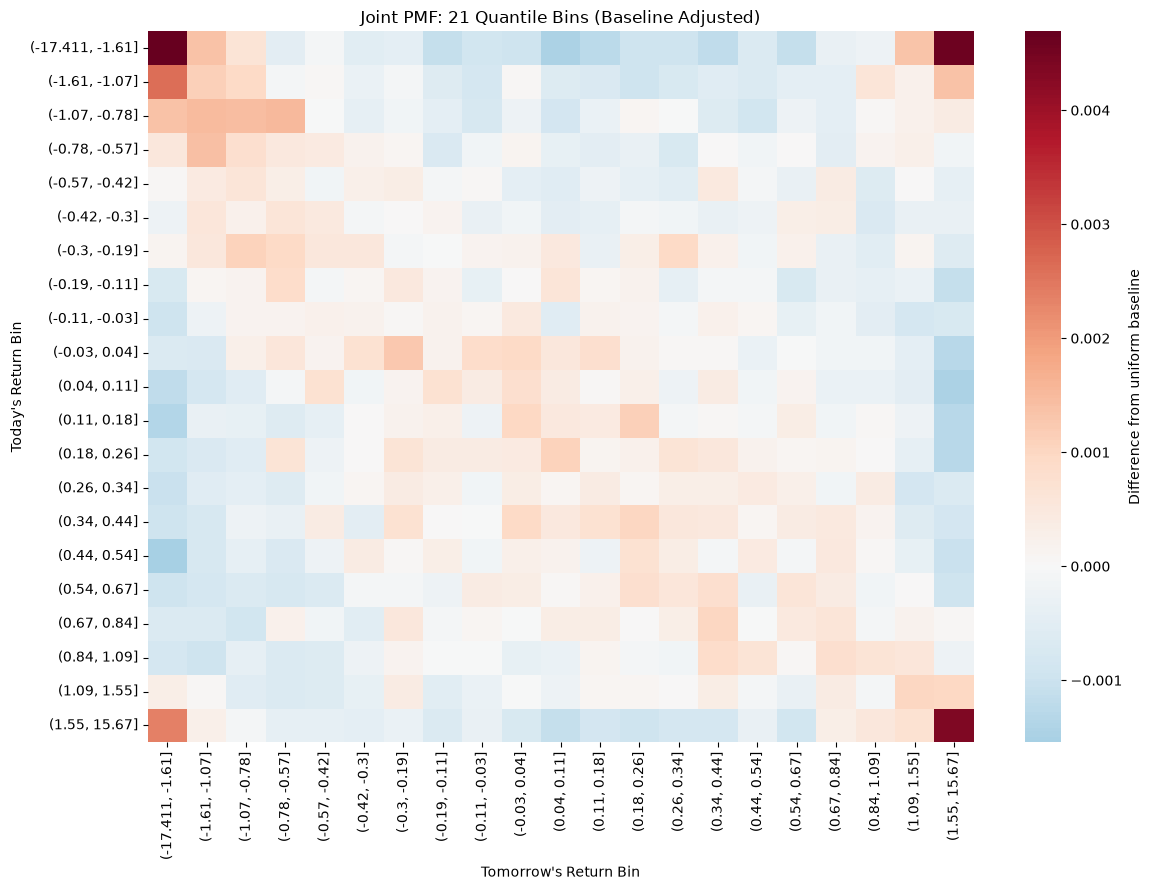

In [17]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    joint_21_subtract,
    cmap='RdBu_r',
    center=0,
    cbar_kws={'label': 'Difference from uniform baseline'}
)

plt.title('Joint PMF: 21 Quantile Bins (Baseline Adjusted)')
plt.xlabel("Tomorrow's Return Bin")
plt.ylabel("Today's Return Bin")
plt.tight_layout()
plt.show()

**Joint PMF: 21 Quantile Bins**

The baseline-adjusted joint PMF heatmap shows several patterns in market returns. The strongest deviations appear in the top-left and bottom-right corners, suggesting that extreme negative and positive returns are more likely to be followed by returns in the same extreme category than under a uniform joint distribution. The middle bins show smaller and more mixed deviations, indicating less pronounced patterns among moderate returns. Overall, the heatmap suggests some persistence in extreme market movements, although these patterns alone do not establish reliable predictability.

In [18]:
# Calculate the conditional PMF
conditional_21 = pd.crosstab(
    df['y_t'],
    df['y_tp1'],
    normalize='index'
)

display(conditional_21)

y_tp1,"(-17.411, -1.61]","(-1.61, -1.07]","(-1.07, -0.78]","(-0.78, -0.57]","(-0.57, -0.42]","(-0.42, -0.3]","(-0.3, -0.19]","(-0.19, -0.11]","(-0.11, -0.03]","(-0.03, 0.04]",...,"(0.11, 0.18]","(0.18, 0.26]","(0.26, 0.34]","(0.34, 0.44]","(0.44, 0.54]","(0.54, 0.67]","(0.67, 0.84]","(0.84, 1.09]","(1.09, 1.55]","(1.55, 15.67]"
y_t,,,,,,,,,,,,,,,,,,,,,
"(-17.411, -1.61]",0.145817,0.076494,0.061355,0.037450,0.046215,0.036653,0.038247,0.023904,0.028685,0.027888,...,0.021514,0.027888,0.027888,0.023108,0.033466,0.023904,0.040637,0.042231,0.075697,0.144223
"(-1.61, -1.07]",0.102155,0.071030,0.067039,0.046289,0.048683,0.041500,0.046289,0.035116,0.030327,0.048683,...,0.032721,0.027933,0.031923,0.035914,0.033520,0.038308,0.038308,0.060654,0.052674,0.076616
"(-1.07, -0.78]",0.074650,0.076983,0.076205,0.077760,0.045879,0.038103,0.043546,0.037325,0.030327,0.041991,...,0.040435,0.048212,0.045879,0.033437,0.027994,0.041991,0.037325,0.047434,0.051322,0.054432
"(-0.78, -0.57]",0.057813,0.075781,0.063281,0.057031,0.055469,0.050781,0.048438,0.032031,0.043750,0.049219,...,0.036719,0.039844,0.031250,0.046875,0.043750,0.046875,0.036719,0.050000,0.052344,0.042969
"(-0.57, -0.42]",0.049593,0.057724,0.061789,0.055285,0.045528,0.054472,0.056098,0.046341,0.049593,0.039024,...,0.043902,0.039837,0.037398,0.058537,0.046341,0.041463,0.056911,0.034959,0.048780,0.039837
"(-0.42, -0.3]",0.044046,0.061175,0.053834,0.061990,0.058728,0.047308,0.048940,0.052202,0.041599,0.045677,...,0.039967,0.047308,0.044861,0.041599,0.044046,0.055465,0.056281,0.033442,0.041599,0.041599
"(-0.3, -0.19]",0.045952,0.053975,0.064187,0.061269,0.053975,0.053975,0.042305,0.043034,0.046681,0.047411,...,0.037199,0.049599,0.061269,0.048140,0.040846,0.048140,0.037199,0.033552,0.045952,0.032093
"(-0.19, -0.11]",0.033167,0.051410,0.053068,0.068823,0.047264,0.051410,0.060531,0.053068,0.041459,0.049751,...,0.051410,0.053897,0.040630,0.048093,0.048093,0.033167,0.042289,0.040630,0.043118,0.025705
"(-0.11, -0.03]",0.029215,0.044240,0.053422,0.053422,0.055092,0.054257,0.050918,0.054257,0.051753,0.060100,...,0.054257,0.053422,0.048414,0.055092,0.051753,0.041736,0.046745,0.039232,0.031720,0.033389


In [19]:
# Subtract the uniform conditional probability baseline
conditional_21_subtract = conditional_21 - (1 / 21)

display(conditional_21_subtract)

y_tp1,"(-17.411, -1.61]","(-1.61, -1.07]","(-1.07, -0.78]","(-0.78, -0.57]","(-0.57, -0.42]","(-0.42, -0.3]","(-0.3, -0.19]","(-0.19, -0.11]","(-0.11, -0.03]","(-0.03, 0.04]",...,"(0.11, 0.18]","(0.18, 0.26]","(0.26, 0.34]","(0.34, 0.44]","(0.44, 0.54]","(0.54, 0.67]","(0.67, 0.84]","(0.84, 1.09]","(1.09, 1.55]","(1.55, 15.67]"
y_t,,,,,,,,,,,,,,,,,,,,,
"(-17.411, -1.61]",0.098198,0.028875,0.013736,-0.010169,-0.001404,-0.010966,-0.009372,-0.023715,-0.018934,-0.019731,...,-0.026105,-0.019731,-0.019731,-0.024511,-0.014153,-0.023715,-0.006982,-0.005388,0.028078,0.096604
"(-1.61, -1.07]",0.054536,0.023410,0.019420,-0.001330,0.001064,-0.006119,-0.001330,-0.012503,-0.017292,0.001064,...,-0.014898,-0.019686,-0.015696,-0.011705,-0.014099,-0.009311,-0.009311,0.013035,0.005055,0.028997
"(-1.07, -0.78]",0.027031,0.029364,0.028586,0.030141,-0.001740,-0.009516,-0.004073,-0.010294,-0.017292,-0.005628,...,-0.007184,0.000592,-0.001740,-0.014182,-0.019625,-0.005628,-0.010294,-0.000185,0.003703,0.006813
"(-0.78, -0.57]",0.010193,0.028162,0.015662,0.009412,0.007850,0.003162,0.000818,-0.015588,-0.003869,0.001600,...,-0.010900,-0.007775,-0.016369,-0.000744,-0.003869,-0.000744,-0.010900,0.002381,0.004725,-0.004650
"(-0.57, -0.42]",0.001974,0.010105,0.014170,0.007666,-0.002091,0.006852,0.008479,-0.001278,0.001974,-0.008595,...,-0.003717,-0.007782,-0.010221,0.010918,-0.001278,-0.006156,0.009292,-0.012660,0.001161,-0.007782
"(-0.42, -0.3]",-0.003573,0.013556,0.006215,0.014371,0.011109,-0.000311,0.001321,0.004583,-0.006020,-0.001942,...,-0.007652,-0.000311,-0.002758,-0.006020,-0.003573,0.007846,0.008662,-0.014177,-0.006020,-0.006020
"(-0.3, -0.19]",-0.001667,0.006356,0.016568,0.013650,0.006356,0.006356,-0.005314,-0.004585,-0.000938,-0.000208,...,-0.010420,0.001980,0.013650,0.000521,-0.006773,0.000521,-0.010420,-0.014067,-0.001667,-0.015526
"(-0.19, -0.11]",-0.014452,0.003791,0.005449,0.021204,-0.000355,0.003791,0.012912,0.005449,-0.006160,0.002132,...,0.003791,0.006278,-0.006989,0.000474,0.000474,-0.014452,-0.005330,-0.006989,-0.004501,-0.021914
"(-0.11, -0.03]",-0.018404,-0.003379,0.005803,0.005803,0.007473,0.006638,0.003299,0.006638,0.004134,0.012481,...,0.006638,0.005803,0.000795,0.007473,0.004134,-0.005883,-0.000874,-0.008387,-0.015900,-0.014230


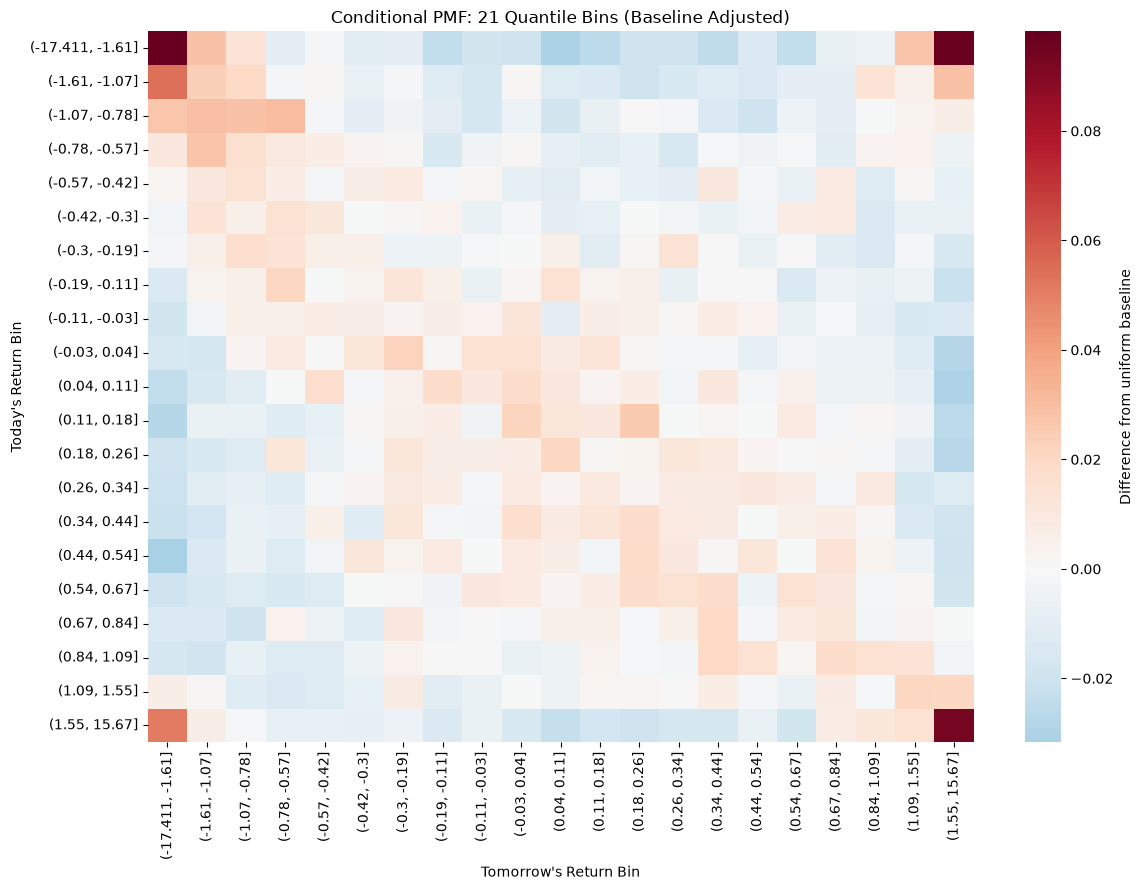

In [20]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    conditional_21_subtract,
    cmap='RdBu_r',
    center=0,
    cbar_kws={'label': 'Difference from uniform baseline'}
)

plt.title('Conditional PMF: 21 Quantile Bins (Baseline Adjusted)')
plt.xlabel("Tomorrow's Return Bin")
plt.ylabel("Today's Return Bin")
plt.tight_layout()
plt.show()

**Conditional PMF: 21 Quantile Bins**

The baseline-adjusted conditional PMF shows patterns similar to the joint PMF. The strongest positive deviations appear in the extreme negative and positive return categories, suggesting that extreme returns are more likely to be followed by returns in the same extreme category. The middle bins show smaller and more mixed deviations, indicating less consistent patterns among moderate returns. Overall, the results suggest some persistence in extreme market movements, but probabilities remain distributed across multiple possible outcomes, making precise next-day predictions difficult.

In [21]:
# Calculate tomorrow's return for each of the 21 bins
df['market_return_pct_tp1'] = df['market_return_pct'].shift(-1)

# Calculate descriptive statistics by today's return bin
stats_21 = (
    df.groupby('y_t', observed=False)['market_return_pct_tp1']
      .describe()
)

display(stats_21)

,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
"(-17.411, -1.61]",1255.0,-0.013713,2.140465,-17.41,-0.9150,-0.02,0.9000,11.22
"(-1.61, -1.07]",1253.0,-0.076712,1.285882,-7.36,-0.7400,-0.02,0.6000,6.36
"(-1.07, -0.78]",1286.0,-0.097084,1.227976,-8.79,-0.7100,-0.03,0.4700,11.36
"(-0.78, -0.57]",1280.0,-0.058594,1.049607,-8.28,-0.5800,0.00,0.4925,6.16
"(-0.57, -0.42]",1230.0,-0.024211,0.989470,-6.89,-0.4675,0.02,0.4675,4.56
"(-0.42, -0.3]",1226.0,-0.022692,1.024761,-11.23,-0.4975,0.02,0.5000,6.37
"(-0.3, -0.19]",1371.0,-0.030241,0.930389,-3.94,-0.4950,0.03,0.4100,7.37
"(-0.19, -0.11]",1206.0,-0.014303,0.835663,-3.40,-0.4200,0.03,0.4100,4.76
"(-0.11, -0.03]",1198.0,0.025860,0.853220,-6.00,-0.3900,0.03,0.4400,5.49


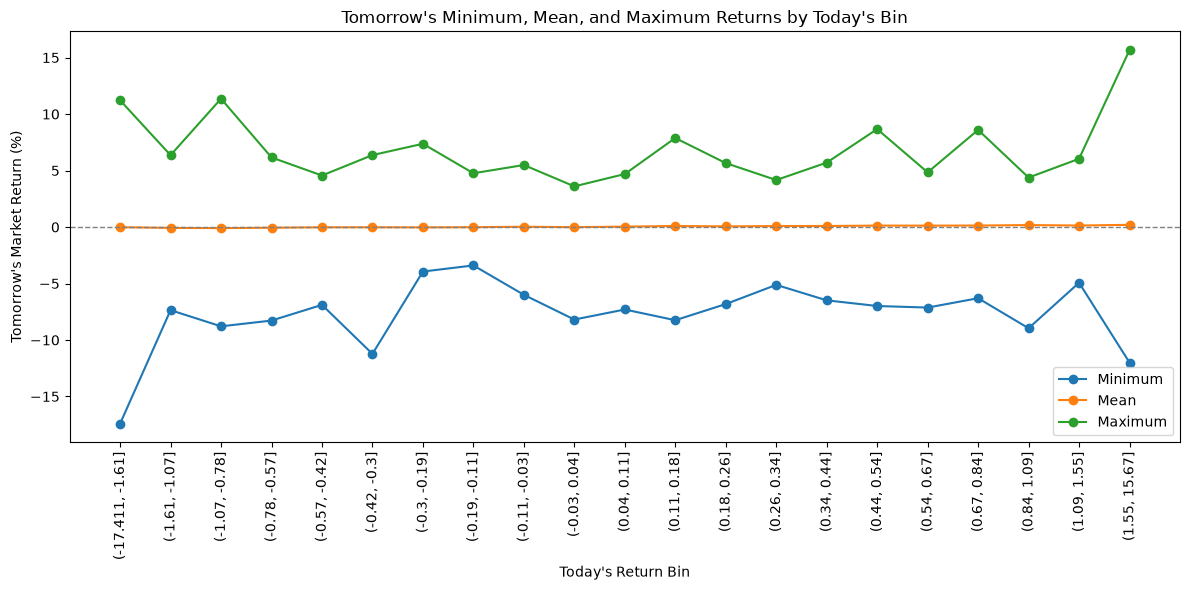

In [22]:
plt.figure(figsize=(12, 6))

plt.plot(stats_21.index.astype(str), stats_21['min'],
         marker='o', label='Minimum')

plt.plot(stats_21.index.astype(str), stats_21['mean'],
         marker='o', label='Mean')

plt.plot(stats_21.index.astype(str), stats_21['max'],
         marker='o', label='Maximum')

plt.axhline(0, color='gray', linestyle='--', linewidth=1)

plt.title("Tomorrow's Minimum, Mean, and Maximum Returns by Today's Bin")
plt.xlabel("Today's Return Bin")
plt.ylabel("Tomorrow's Market Return (%)")
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.show()

**Next-Day Minimum, Mean, and Maximum Returns**

The graph shows that tomorrow's mean returns remain close to zero across all 21 bins, suggesting little variation in expected returns based on today's category. In contrast, the minimum and maximum returns fluctuate considerably. The most extreme negative return occurs after the lowest return bin, while the highest positive return occurs after the highest return bin. Overall, there is no consistent trend in the minimum or maximum values, although extreme returns can be followed by similarly extreme outcomes.

In [23]:
# Calculate tomorrow's standard deviation for each bin
std_21 = (
    df.groupby('y_t', observed=False)['market_return_pct_tp1']
      .std()
)

display(std_21)

y_t
(-17.411, -1.61]    2.140465
(-1.61, -1.07]      1.285882
(-1.07, -0.78]      1.227976
(-0.78, -0.57]      1.049607
(-0.57, -0.42]      0.989470
(-0.42, -0.3]       1.024761
(-0.3, -0.19]       0.930389
(-0.19, -0.11]      0.835663
(-0.11, -0.03]      0.853220
(-0.03, 0.04]       0.811559
(0.04, 0.11]        0.805212
(0.11, 0.18]        0.791857
(0.18, 0.26]        0.784100
(0.26, 0.34]        0.816509
(0.34, 0.44]        0.831233
(0.44, 0.54]        0.789961
(0.54, 0.67]        0.826667
(0.67, 0.84]        0.959673
(0.84, 1.09]        0.900844
(1.09, 1.55]        1.099897
(1.55, 15.67]       1.702623
Name: market_return_pct_tp1, dtype: float64

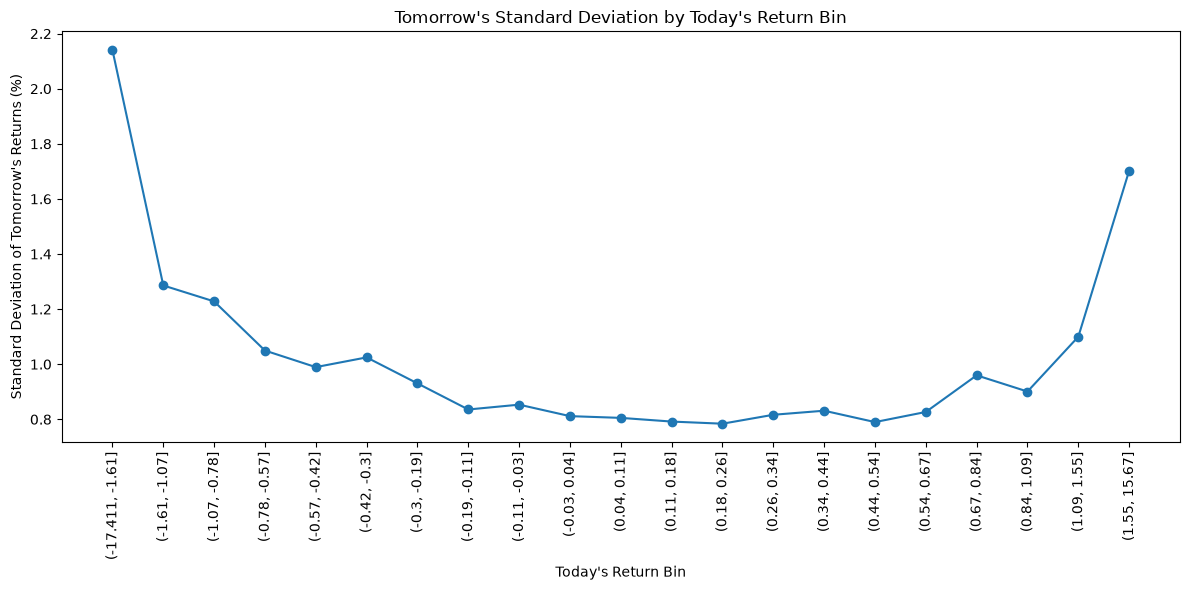

In [24]:
plt.figure(figsize=(12, 6))

plt.plot(
    std_21.index.astype(str),
    std_21.values,
    marker='o'
)

plt.title("Tomorrow's Standard Deviation by Today's Return Bin")
plt.xlabel("Today's Return Bin")
plt.ylabel("Standard Deviation of Tomorrow's Returns (%)")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

**How Easy Is It to Predict the Market?**

Overall, predicting the market is difficult. Although the analysis reveals some patterns, such as persistence among extreme returns and higher volatility following extreme market movements, tomorrow's average returns remain close to zero and individual returns vary considerably. Today's return category provides some information about tomorrow's potential behavior, particularly its volatility, but it is not enough to reliably predict the direction or exact size of the next day's return.